<a href="https://colab.research.google.com/github/Marcos-oss-cloud/superstore-sales-analysis/blob/main/An%C3%A1lise_Estrat%C3%A9gica_MKT_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import data_table

# Ativa o visualizador interativo elegante do Colab
data_table.enable_dataframe_formatter()

# 1. Carregar as 7 bases individualmente
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')


display(customers.head(10))


#Serve para exibição em modo de tabela da base



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [ ]:


# 1. CARREGAR AS 7 BASES (Incluindo a de Clientes)
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv') # ESSENCIAL para a RFM
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')


# 2. INTEGRAR AS BASES
df = pd.merge(items, orders, on='order_id', how='left')
df = pd.merge(df, customers, on='customer_id', how='left') # Garante o customer_unique_id
df = pd.merge(df, payments, on='order_id', how='left')
df = pd.merge(df, reviews, on='order_id', how='left')
df = pd.merge(df, products, on='product_id', how='left')
df = pd.merge(df, translation, on='product_category_name', how='left')



# 3. FILTRAR STATUS VÁLIDOS
# Para análise de faturamento, RFM e portfólio, consideramos apenas pedidos entregues
df = df[df['order_status'] == 'delivered'].copy()



# 4. CONVERSÃO DE DATAS
colunas_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in colunas_data:
    df[col] = pd.to_datetime(df[col])


# 5. TRATAMENTO DE VALORES NULOS E DUPLICADAS
df['product_category_name_english'] = df['product_category_name_english'].fillna('others')
df['product_category_name'] = df['product_category_name'].fillna('nao_informado')
df = df.drop_duplicates()


# 6. ENGENHARIA DE RECURSOS PARA OS OBJETIVOS DO PROJETO

# A) Suporte para Sazonalidade (Análises Temporais)
df['ano'] = df['order_purchase_timestamp'].dt.year
df['mes'] = df['order_purchase_timestamp'].dt.month
df['ano_mes'] = df['order_purchase_timestamp'].dt.to_period('M')
df['dia_da_semana'] = df['order_purchase_timestamp'].dt.day_name()

# B) Suporte para Curva ABC e Portfólio
df['valor_total_item'] = df['price'] + df['freight_value']


# 7. CONFIRMAÇÃO DO RESULTADO
print("=== BASE LIMPA E PREPARADA ===")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print(f"Clientes Únicos Mapeados: {df['customer_unique_id'].nunique()}")

=== BASE LIMPA E PREPARADA ===
Linhas: 115723 | Colunas: 42
Clientes Únicos Mapeados: 93358


In [ ]:
# Seleciona apenas as colunas de data de compra e status para ver as 5 primeiras linhas
orders[['order_purchase_timestamp', 'order_status']].head()


,order_purchase_timestamp,order_status
0,2017-10-02 10:56:33,delivered
1,2018-07-24 20:41:37,delivered
2,2018-08-08 08:38:49,delivered
3,2017-11-18 19:28:06,delivered
4,2018-02-13 21:18:39,delivered


In [ ]:
orders['order_status'].value_counts()

#similar a tabela dinâmica


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [ ]:
orders['order_status'].value_counts(normalize=True) * 100

# ótimo! serve para analisar a taxa de proporção. muito importante para seguimentos de análises!

,proportion
order_status,
delivered,97.020344
shipped,1.113223
canceled,0.628513
unavailable,0.612423
invoiced,0.315765
processing,0.302692
created,0.005028
approved,0.002011


In [ ]:
#filtrar uma qntd específica

#parte de fora serve para mostrar se é verdadeiro ou falso

orders_entregues=orders[orders['order_status']=='delivered']
print("Total de pedidos inicialmente:", len(orders))
print("Total de pedidos entregues:", len(orders_entregues))


Total de pedidos inicialmente: 99441
Total de pedidos entregues: 96478


In [ ]:
#conversão de coluna para tipo de data
orders_entregues['order_purchase_timestamp'] = pd.to_datetime(orders_entregues['order_purchase_timestamp'])


#criar nova coluna de mês e ano
orders_entregues['ano']=orders_entregues['order_purchase_timestamp'].dt.year
orders_entregues['mes_nome']=orders_entregues['order_purchase_timestamp'].dt.month_name()



#visualizar as colunas
orders_entregues[['order_purchase_timestamp', 'ano', 'mes_nome']].head()



/tmp/ipykernel_1028/3546391913.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders_entregues['order_purchase_timestamp'] = pd.to_datetime(orders_entregues['order_purchase_timestamp'])
/tmp/ipykernel_1028/3546391913.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders_entregues['ano']=orders_entregues['order_purchase_timestamp'].dt.year
/tmp/ipykernel_1028/3546391913.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

,order_purchase_timestamp,ano,mes_nome
0,2017-10-02 10:56:33,2017,October
1,2018-07-24 20:41:37,2018,July
2,2018-08-08 08:38:49,2018,August
3,2017-11-18 19:28:06,2017,November
4,2018-02-13 21:18:39,2018,February


In [ ]:
pedidos_por_ano = orders_entregues.groupby('ano')['order_id'].count()

print('===TOTAL DE PEDIDOS ENTREGUES POR ANO===')
print(pedidos_por_ano)

===TOTAL DE PEDIDOS ENTREGUES POR ANO===
ano
2016      267
2017    43428
2018    52783
Name: order_id, dtype: int64


###VISÃO MENSAL



In [ ]:

# 1. Converter a coluna para datetime primeiro
orders_entregues['order_purchase_timestamp'] = pd.to_datetime(orders_entregues['order_purchase_timestamp'])

# 2. Criar a coluna de Ano-Mês (com underscore para padronizar)
orders_entregues['ano_mes'] = orders_entregues['order_purchase_timestamp'].dt.to_period('M')

# 3. Agrupar os pedidos por Ano-Mês
vendas_mensais = orders_entregues.groupby('ano_mes')['order_id'].count()

print("=== Evolução Mensal dos Pedidos ===")
print(vendas_mensais)
print("===Evolução Mensal dos Pedidos===")
print(vendas_mensais)


#se coloco aspas aqui no último print, ele entende como string e não lê de maneira correta

=== Evolução Mensal dos Pedidos ===
ano_mes
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64
===Evolução Mensal dos Pedidos===
ano_mes
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64


/tmp/ipykernel_1028/368456089.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders_entregues['order_purchase_timestamp'] = pd.to_datetime(orders_entregues['order_purchase_timestamp'])
/tmp/ipykernel_1028/368456089.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders_entregues['ano_mes'] = orders_entregues['order_purchase_timestamp'].dt.to_period('M')


<Axes: title={'center': 'Evolução Mensal de Pedidos - Olist'}, xlabel='ano_mes'>

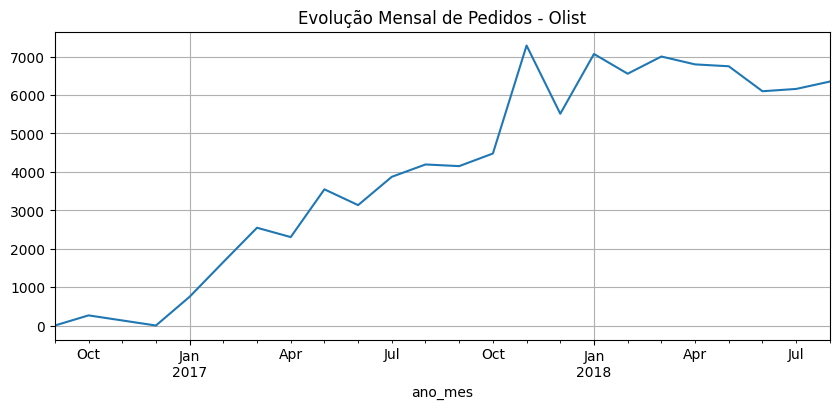

In [ ]:
vendas_mensais.plot(
    kind='line',
    figsize=(10, 4),
    title='Evolução Mensal de Pedidos - Olist',
    grid=True
)

# Faturamento e Ticket Médio

In [ ]:
#1. Carregar a base de itens:
items = pd.read_csv('olist_order_items_dataset.csv')


#2. Fazer a junção PROCV entre pedidos entregues e itens pelo 'order_id'

df_vendas = pd.merge(orders_entregues, items, on='order_id', how='inner')


#3. Métricas financeiras principais

faturamento_total=df_vendas['price'].sum()
frete_total = df_vendas['freight_value'].sum()
ticket_medio = df_vendas.groupby('order_id')['price'].sum().mean()



#4. Exibição dos resultados

print(f"Faturamento Total em Produtos: R$ {faturamento_total:,.2f}")
print(f"Total Gasto em Frete: R$ {frete_total:,.2f}")
print(f"Ticket Médio por Pedido: R$ {ticket_medio:.2f}")




Faturamento Total em Produtos: R$ 13,221,498.11
Total Gasto em Frete: R$ 2,198,275.64
Ticket Médio por Pedido: R$ 137.04


Curva da Receita Mensal


=== FATURAMENTO MENSAL (R$) ===
ano_mes
2016-09        R$ 134.97
2016-10     R$ 40,325.11
2016-12         R$ 10.90
2017-01    R$ 111,798.36
2017-02    R$ 234,223.40
2017-03    R$ 359,198.85
2017-04    R$ 340,669.68
2017-05    R$ 489,338.25
2017-06    R$ 421,923.37
2017-07    R$ 481,604.52
2017-08    R$ 554,699.70
2017-09    R$ 607,399.67
2017-10    R$ 648,247.65
2017-11    R$ 987,765.37
2017-12    R$ 726,033.19
2018-01    R$ 924,645.00
2018-02    R$ 826,437.13
2018-03    R$ 953,356.25
2018-04    R$ 973,534.09
2018-05    R$ 977,544.69
2018-06    R$ 856,077.86
2018-07    R$ 867,953.46
2018-08    R$ 838,576.64
Freq: M, Name: price, dtype: object


<Axes: title={'center': 'Evolução do Faturamento Mensal (R$) - Olist'}, xlabel='ano_mes'>

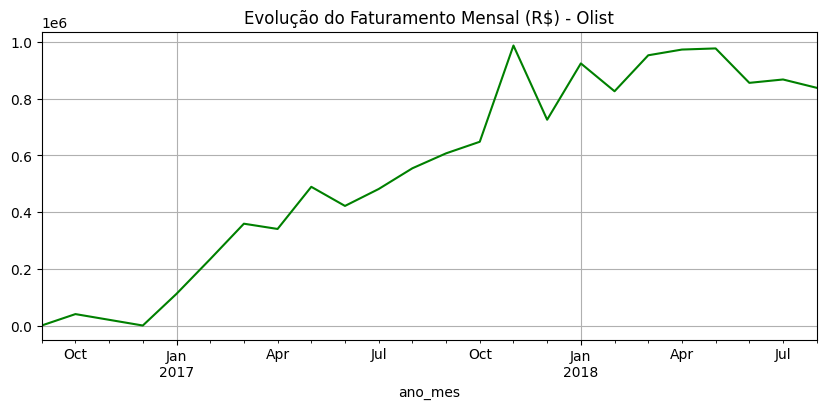

In [ ]:
# 1. Agrupar o faturamento total (soma do preço) por mês
faturamento_mensal = df_vendas.groupby('ano_mes')['price'].sum()

# 2. Exibir os valores formatados em Reais
print("=== FATURAMENTO MENSAL (R$) ===")
print(faturamento_mensal.apply(lambda x: f"R$ {x:,.2f}"))

# 3. Gerar gráfico de linha do faturamento
faturamento_mensal.plot(
    kind='line',
    figsize=(10, 4),
    title='Evolução do Faturamento Mensal (R$) - Olist',
    grid=True,
    color='green'
)

Curva ABC

In [ ]:
# 1. Carregar as bases de produtos e traduções
products = pd.read_csv('olist_products_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')

# 2. Encadeamento de Merges (PROCV em cadeia)
# Unir as vendas com as características dos produtos
df_produtos = pd.merge(df_vendas, products, on='product_id', how='left')

# Unir com a tabela de tradução para ter os nomes das categorias em inglês/português
df_completo = pd.merge(df_produtos, translation, on='product_category_name', how='left')

# 3. Agrupar faturação por categoria e ordenar
curva_abc = df_completo.groupby('product_category_name_english')['price'].sum().reset_index()
curva_abc = curva_abc.sort_values(by='price', ascending=False)

# 4. Cálculo da Curva ABC (% do Total e % Acumulado)
faturamento_total_cat = curva_abc['price'].sum()
curva_abc['pct_share'] = (curva_abc['price'] / faturamento_total_cat) * 100
curva_abc['pct_acumulado'] = curva_abc['pct_share'].cumsum()

# 5. Formatar e exibir o TOP 10 Categorias
curva_abc.head(10).style.format({
    'price': 'R$ {:,.2f}',
    'pct_share': '{:.2f}%',
    'pct_acumulado': '{:.2f}%'
})



##pct_share -> peso percentual de cada categoria sobre o faturamento total.
##

,product_category_name_english,price,pct_share,pct_acumulado
43,health_beauty,"R$ 1,233,131.72",9.45%,9.45%
70,watches_gifts,"R$ 1,166,176.98",8.94%,18.39%
7,bed_bath_table,"R$ 1,023,434.76",7.85%,26.24%
65,sports_leisure,"R$ 954,852.55",7.32%,33.56%
15,computers_accessories,"R$ 888,724.61",6.81%,40.37%
39,furniture_decor,"R$ 711,927.69",5.46%,45.83%
49,housewares,"R$ 615,628.69",4.72%,50.55%
20,cool_stuff,"R$ 610,204.10",4.68%,55.22%
5,auto,"R$ 578,966.65",4.44%,59.66%
69,toys,"R$ 471,286.48",3.61%,63.27%


### Análise de RFM (Recência, Frequência e Valor Monetário)
Nesta seção, calculamos as métricas de RFM para cada cliente utilizando o DataFrame `df` que já possui os dados integrados e limpos.

In [ ]:
import numpy as np
import pandas as pd

# 1. Data de referência
data_referencia = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# 2. Agrupamento e cálculo das métricas RFM
rfm = df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (data_referencia - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id', 'Recencia', 'Frequencia', 'Monetario']

# 3. Atribuição das pontuações (scores de 1 a 5)
rfm['R_Score'] = pd.qcut(rfm['Recencia'], q=5, labels=[5, 4, 3, 2, 1])

rfm['F_Score'] = pd.cut(
    rfm['Frequencia'],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[1, 2, 3, 4, 5],
    right=True
)

rfm['M_Score'] = pd.qcut(rfm['Monetario'], q=5, labels=[1, 2, 3, 4, 5])

# 4. Consolidação do segmento e média
rfm['RFM_Segmento'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Score_Medio'] = rfm[['R_Score', 'F_Score', 'M_Score']].astype(int).mean(axis=1)

# 5. Mapeamento dos segmentos
def segmentar_cliente(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])

    if r >= 4 and f >= 3 and m >= 4:
        return 'Campeões'
    elif r >= 3 and f >= 2:
        return 'Clientes Leais'
    elif r >= 4 and f == 1:
        return 'Novos Clientes'
    elif r <= 2 and m >= 4:
        return 'Clientes de Risco (Gasto Alto)'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Perdidos'
    else:
        return 'Potenciais / Regular'

rfm['Segmento'] = rfm.apply(segmentar_cliente, axis=1)

### Visualização da Distribuição dos Segmentos RFM
Vamos plotar um gráfico para entender a proporção de cada segmento de clientes mapeado.

/tmp/ipykernel_1028/1787008975.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segmentos_dist, x='Quantidade', y='Segmento', palette='Blues_r')


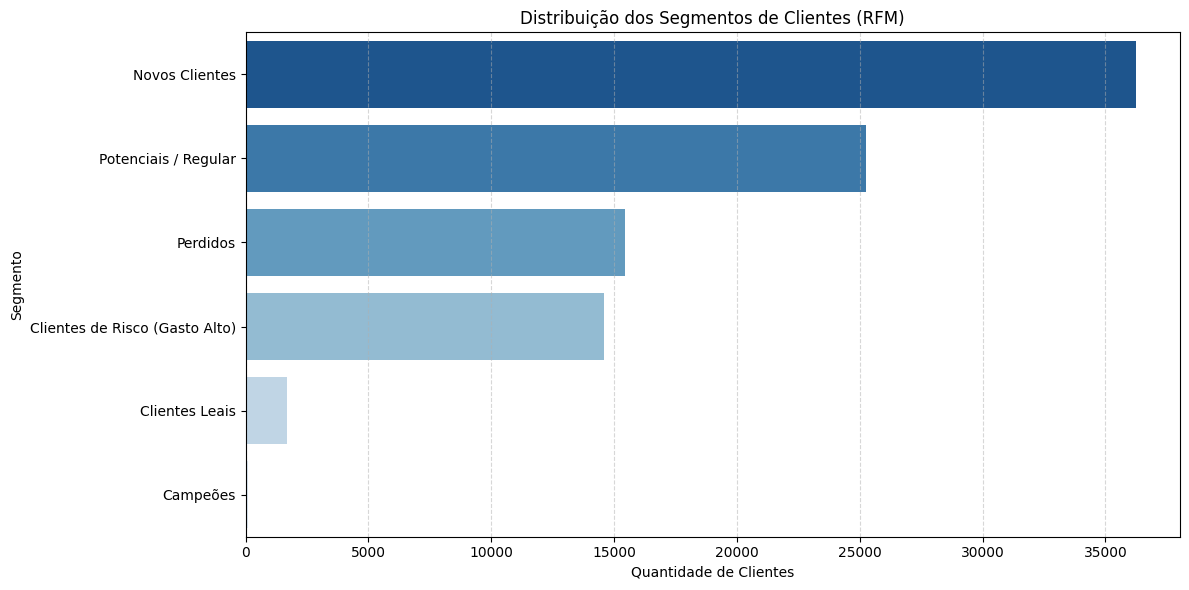

,Segmento,Quantidade,Percentual
0,Novos Clientes,36224,38.801174
1,Potenciais / Regular,25270,27.067846
2,Perdidos,15441,16.539557
3,Clientes de Risco (Gasto Alto),14610,15.649436
4,Clientes Leais,1699,1.819876
5,Campeões,114,0.122111


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupar dados de segmentos
segmentos_dist = rfm['Segmento'].value_counts().reset_index()
segmentos_dist.columns = ['Segmento', 'Quantidade']
segmentos_dist['Percentual'] = (segmentos_dist['Quantidade'] / segmentos_dist['Quantidade'].sum()) * 100

# Plotar gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(data=segmentos_dist, x='Quantidade', y='Segmento', palette='Blues_r')

plt.title('Distribuição dos Segmentos de Clientes (RFM)')
plt.xlabel('Quantidade de Clientes')
plt.ylabel('Segmento')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

display(segmentos_dist)

### Sazonalidade por Categoria de Produto
Agora vamos mapear quais meses apresentam picos de vendas para as principais categorias de produtos.

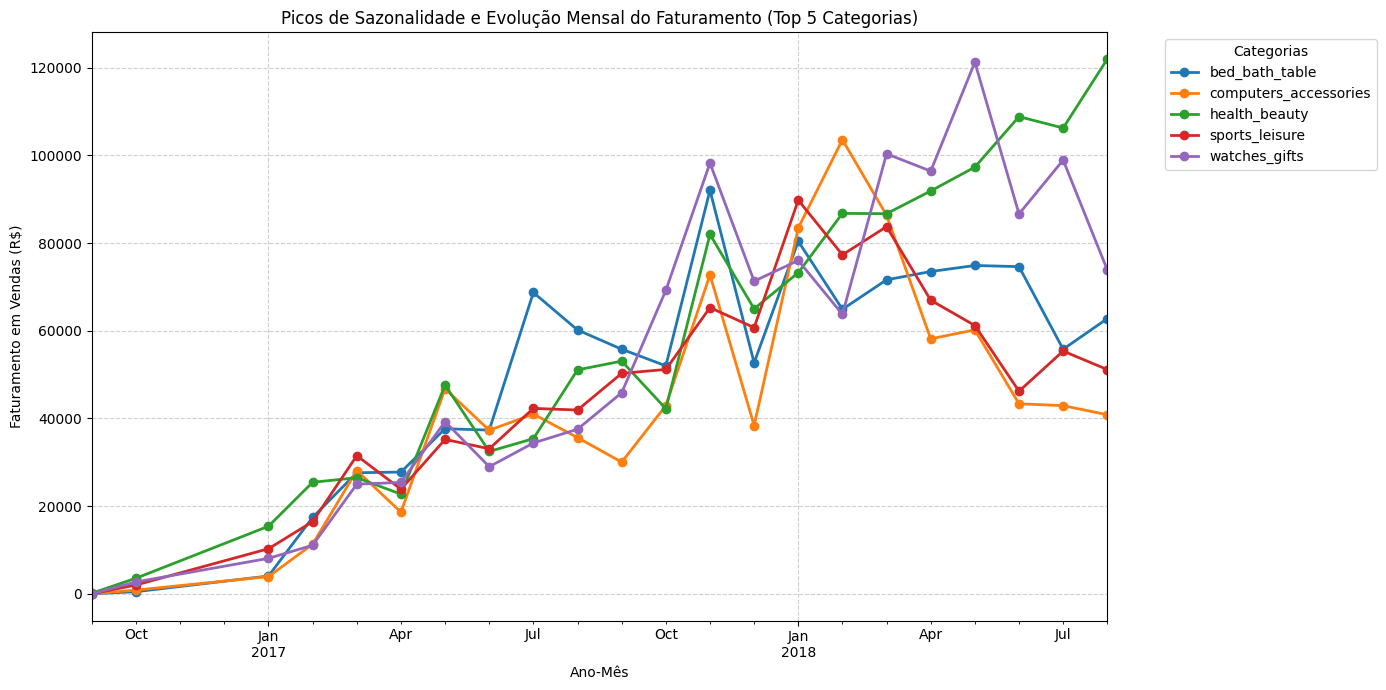

In [ ]:
# 1. Identificar as 5 principais categorias de produtos pelo faturamento total
top_5_categorias = df.groupby('product_category_name_english')['price'].sum().nlargest(5).index.tolist()

# 2. Filtrar o DataFrame principal apenas para estas top 5 categorias
df_top5 = df[df['product_category_name_english'].isin(top_5_categorias)].copy()

# 3. Agrupar por Categoria e Mês (ano_mes) para ver a evolução temporal
sazonalidade_cat = df_top5.groupby(['ano_mes', 'product_category_name_english'])['price'].sum().unstack().fillna(0)

# 4. Plotar a evolução mensal para identificar os picos de sazonalidade
sazonalidade_cat.plot(figsize=(14, 7), marker='o', linewidth=2)
plt.title('Picos de Sazonalidade e Evolução Mensal do Faturamento (Top 5 Categorias)')
plt.xlabel('Ano-Mês')
plt.ylabel('Faturamento em Vendas (R$)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Categorias', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Análise de Logística (Prazos de Entrega) e Meios de Pagamento

Nesta seção, realizamos duas análises fundamentais para o negócio:
1. **Logística**: Avaliação do tempo real de entrega em dias e a taxa de cumprimento de prazos (antecipação ou atraso frente ao estimado).
2. **Meios de Pagamento**: Identificação da preferência dos clientes e do faturamento gerado por cada modalidade de pagamento.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. ANÁLISE DE LOGÍSTICA ---
# Garantindo que as colunas de data estejam no formato datetime
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])

# Dias úteis/corridos reais para entrega
df['tempo_entrega_real'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days

# Dias de diferença frente ao prazo estimado (positivo = antes do prazo, negativo = atrasado)
df['dias_antecipacao'] = (df['order_estimated_delivery_date'] - df['order_delivered_customer_date']).dt.days

print("=== MÉTRICAS DE LOGÍSTICA (EM DIAS) ===")
print(f"Tempo Médio para Entrega ao Cliente: {df['tempo_entrega_real'].mean():.1f} dias")
print(f"Média de Dias de Antecipação (Estimado vs Real): {df['dias_antecipacao'].mean():.1f} dias")

# Taxa de entregas no prazo
entregas_no_prazo = (df['dias_antecipacao'] >= 0).mean() * 100
print(f"Taxa de Sucesso de Entrega no Prazo: {entregas_no_prazo:.2f}%")

=== MÉTRICAS DE LOGÍSTICA (EM DIAS) ===
Tempo Médio para Entrega ao Cliente: 12.0 dias
Média de Dias de Antecipação (Estimado vs Real): 11.0 dias
Taxa de Sucesso de Entrega no Prazo: 92.16%


In [ ]:
# --- 2. ANÁLISE DOS MEIOS DE PAGAMENTO ---
pagamentos_resumo = df.groupby('payment_type').agg(
    quantidade_pedidos=('order_id', 'nunique'),
    faturamento_total=('price', 'sum')
).reset_index().sort_values(by='faturamento_total', ascending=False)

pagamentos_resumo['pct_faturamento'] = (pagamentos_resumo['faturamento_total'] / pagamentos_resumo['faturamento_total'].sum()) * 100

print("\n=== RESUMO DOS MEIOS DE PAGAMENTO ===")
display(pagamentos_resumo.style.format({
    'quantidade_pedidos': '{:,}',
    'faturamento_total': 'R$ {:,.2f}',
    'pct_faturamento': '{:.2f}%'
}))


=== RESUMO DOS MEIOS DE PAGAMENTO ===


,payment_type,quantidade_pedidos,faturamento_total,pct_faturamento
1,credit_card,"74,304","R$ 10,715,579.37",77.22%
0,boleto,"19,191","R$ 2,343,670.49",16.89%
3,voucher,"3,679","R$ 638,494.98",4.60%
2,debit_card,"1,485","R$ 178,591.92",1.29%


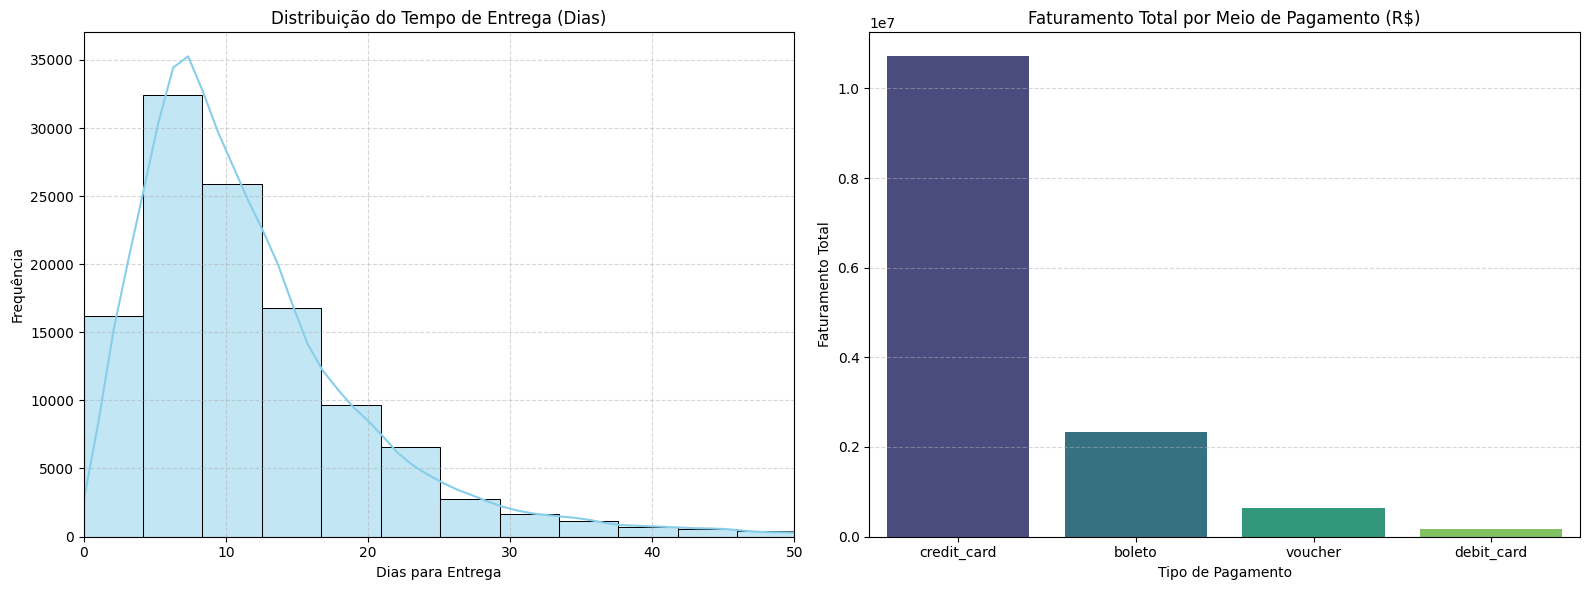

In [ ]:
# --- 3. VISUALIZAÇÃO GRÁFICA ---
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Distribuição do Tempo de Entrega Real
sns.histplot(df['tempo_entrega_real'].dropna(), bins=50, kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribuição do Tempo de Entrega (Dias)')
ax[0].set_xlabel('Dias para Entrega')
ax[0].set_ylabel('Frequência')
ax[0].set_xlim(0, 50)
ax[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Participação no Faturamento por Tipo de Pagamento
sns.barplot(x='payment_type', y='faturamento_total', data=pagamentos_resumo, ax=ax[1], palette='viridis', hue='payment_type', legend=False)
ax[1].set_title('Faturamento Total por Meio de Pagamento (R$)')
ax[1].set_xlabel('Tipo de Pagamento')
ax[1].set_ylabel('Faturamento Total')
ax[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Análise Geográfica de Vendas
Nesta seção, analisamos a distribuição regional do faturamento, volume de pedidos e o ticket médio de acordo com o estado (`customer_state`) do cliente.

In [ ]:
# 1. Agrupar os dados por estado do cliente
analise_geografica = df.groupby('customer_state').agg(
    quantidade_pedidos=('order_id', 'nunique'),
    faturamento_total=('price', 'sum')
).reset_index()

# Calcular o ticket médio por estado
analise_geografica['ticket_medio'] = analise_geografica['faturamento_total'] / analise_geografica['quantidade_pedidos']

# Calcular a participação percentual no faturamento total
analise_geografica['pct_faturamento'] = (analise_geografica['faturamento_total'] / analise_geografica['faturamento_total'].sum()) * 100

# Ordenar pelo faturamento total
analise_geografica = analise_geografica.sort_values(by='faturamento_total', ascending=False).reset_index(drop=True)

print("=== TOP 10 ESTADOS POR FATURAMENTO ===")
display(analise_geografica.head(10).style.format({
    'quantidade_pedidos': '{:,}',
    'faturamento_total': 'R$ {:,.2f}',
    'ticket_medio': 'R$ {:,.2f}',
    'pct_faturamento': '{:.2f}%'
}))

=== TOP 10 ESTADOS POR FATURAMENTO ===


,customer_state,quantidade_pedidos,faturamento_total,ticket_medio,pct_faturamento
0,SP,"40,501","R$ 5,336,384.33",R$ 131.76,38.46%
1,RJ,"12,350","R$ 1,852,549.26",R$ 150.00,13.35%
2,MG,"11,354","R$ 1,612,470.88",R$ 142.02,11.62%
3,RS,"5,345","R$ 769,537.51",R$ 143.97,5.55%
4,PR,"4,923","R$ 691,656.18",R$ 140.49,4.98%
5,SC,"3,546","R$ 525,394.99",R$ 148.17,3.79%
6,BA,"3,256","R$ 522,775.16",R$ 160.56,3.77%
7,DF,"2,080","R$ 308,943.96",R$ 148.53,2.23%
8,GO,"1,957","R$ 301,347.13",R$ 153.98,2.17%
9,ES,"1,995","R$ 278,091.14",R$ 139.39,2.00%


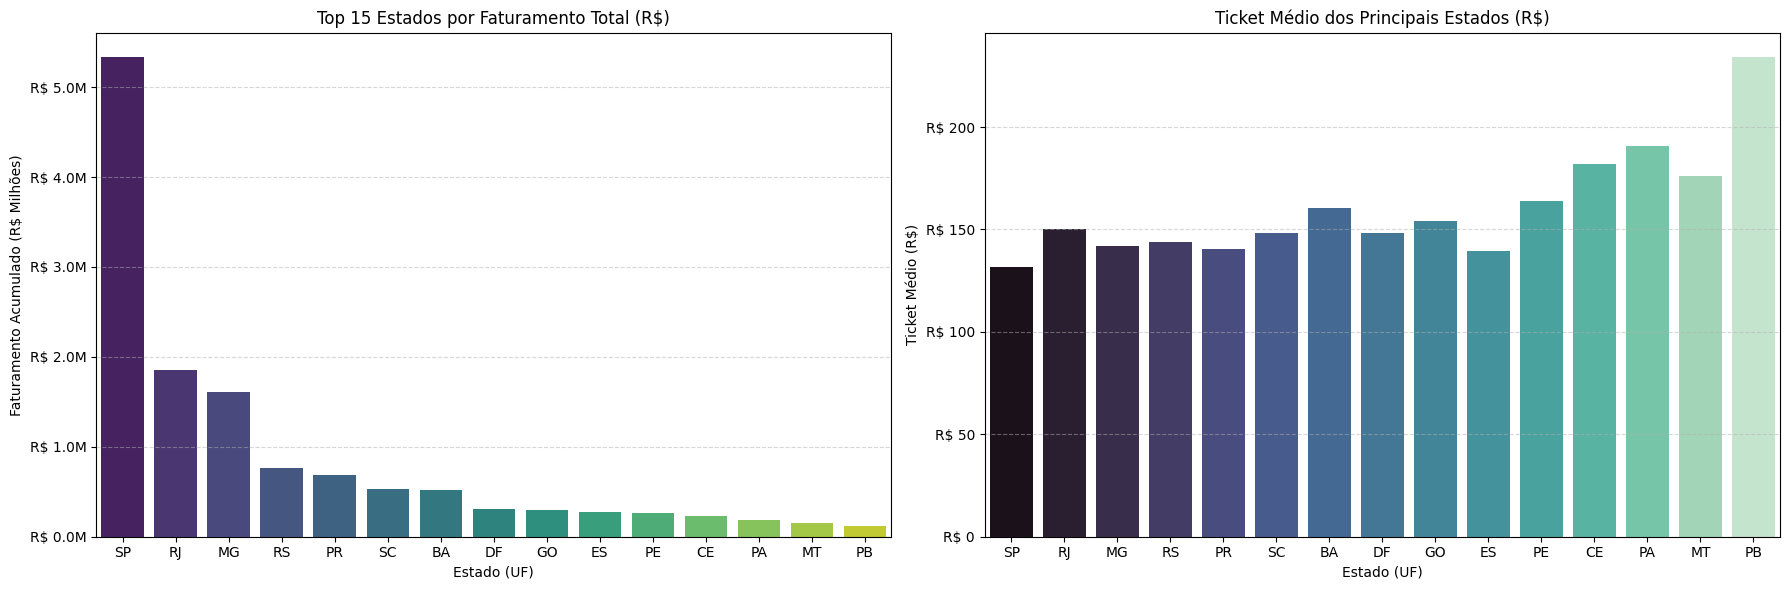

In [ ]:
import matplotlib.ticker as ticker

# 2. Visualização Gráfica da Distribuição Geográfica com Eixos Formatados
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# Gráfico 1: Faturamento Total por Estado
sns.barplot(x='customer_state', y='faturamento_total', data=analise_geografica.head(15), ax=ax[0], palette='viridis', hue='customer_state', legend=False)
ax[0].set_title('Top 15 Estados por Faturamento Total (R$)')
ax[0].set_xlabel('Estado (UF)')
ax[0].set_ylabel('Faturamento Acumulado (R$ Milhões)')

# Formata o eixo Y do primeiro gráfico para mostrar valores em milhões de forma amigável (ex: R$ 5.3M)
formatter_milhoes = ticker.FuncFormatter(lambda x, pos: f'R$ {x*1e-6:.1f}M')
ax[0].yaxis.set_major_formatter(formatter_milhoes)
ax[0].grid(axis='y', linestyle='--', alpha=0.5)

# Gráfico 2: Ticket Médio por Estado (dos top 15 estados em vendas)
sns.barplot(x='customer_state', y='ticket_medio', data=analise_geografica.head(15), ax=ax[1], palette='mako', hue='customer_state', legend=False)
ax[1].set_title('Ticket Médio dos Principais Estados (R$)')
ax[1].set_xlabel('Estado (UF)')
ax[1].set_ylabel('Ticket Médio (R$)')

# Formata o eixo Y do segundo gráfico para moeda simples (R$ 150, etc.)
formatter_moeda = ticker.FuncFormatter(lambda x, pos: f'R$ {x:.0f}')
ax[1].yaxis.set_major_formatter(formatter_moeda)
ax[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##Padronização e Normalização dos Dados

=== COMPARAÇÃO DOS DADOS ORIGINAIS VS PADRONIZADOS (TOP 5) ===


,Recencia,Frequencia,Monetario,Recencia_Scaled,Frequencia_Scaled,Monetario_Scaled
0,112,1,129.90,-0.825357,-0.159829,-0.076353
1,115,1,18.90,-0.805697,-0.159829,-0.528671
2,537,1,69.00,1.959873,-0.159829,-0.324517
3,321,1,25.99,0.544321,-0.159829,-0.499780
4,288,1,180.00,0.328056,-0.159829,0.127801


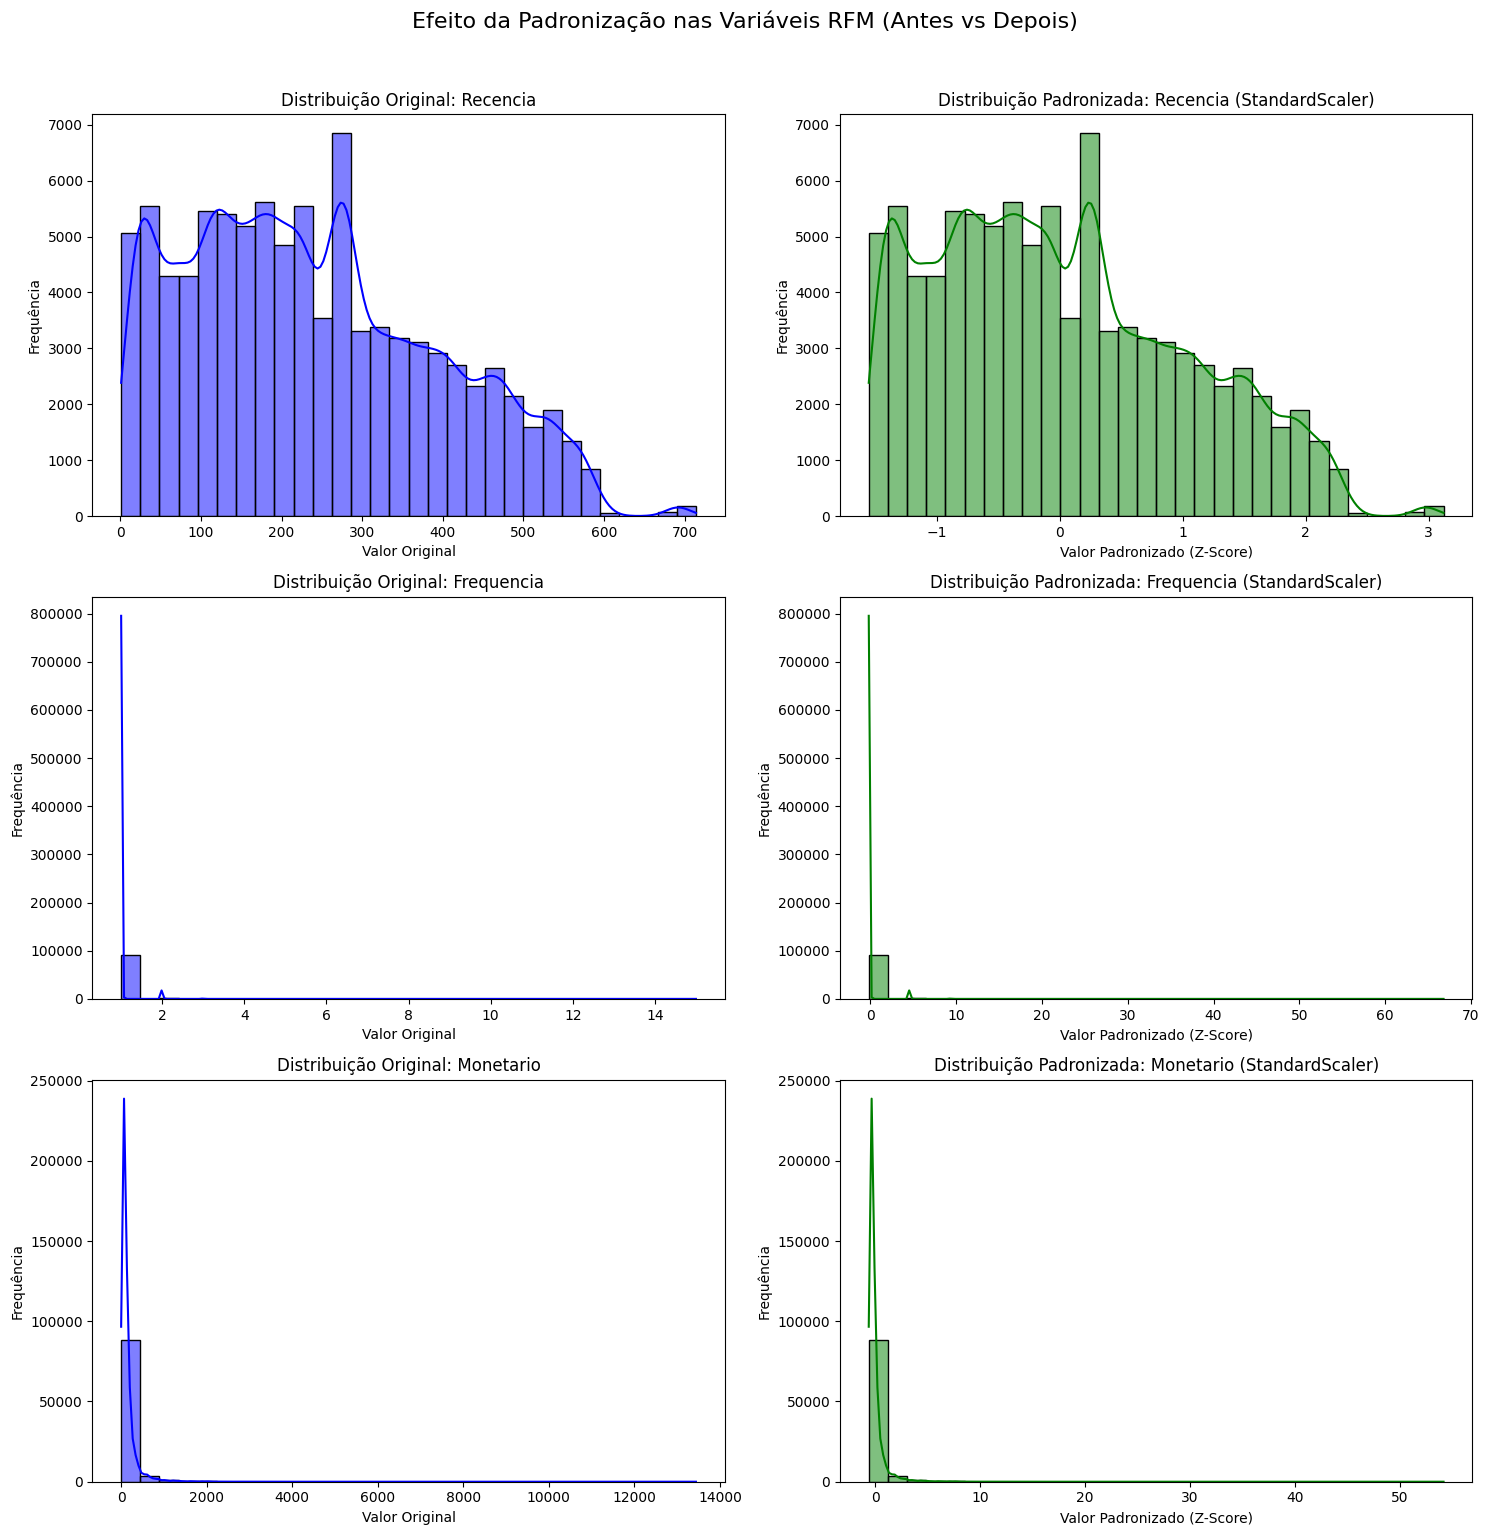

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Selecionar apenas as colunas numéricas do RFM para padronização
colunas_rfm = ['Recencia', 'Frequencia', 'Monetario']
df_rfm_numeric = rfm[colunas_rfm].copy()

# 2. Inicializar e aplicar o StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(df_rfm_numeric)

# Criar um DataFrame com os dados padronizados
df_rfm_scaled = pd.DataFrame(rfm_scaled, columns=[f'{col}_Scaled' for col in colunas_rfm])
df_rfm_scaled['customer_unique_id'] = rfm['customer_unique_id']

# Exibir as primeiras linhas das colunas originais vs padronizadas
print("=== COMPARAÇÃO DOS DADOS ORIGINAIS VS PADRONIZADOS (TOP 5) ===")
display(pd.concat([rfm[colunas_rfm], df_rfm_scaled[[f'{col}_Scaled' for col in colunas_rfm]]], axis=1).head())

# 3. Gerar os gráficos de distribuição (Antes vs Depois)
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for i, col in enumerate(colunas_rfm):
    # Antes da padronização (Original)
    sns.histplot(rfm[col], bins=30, kde=True, ax=axes[i, 0], color='blue')
    axes[i, 0].set_title(f'Distribuição Original: {col}')
    axes[i, 0].set_xlabel('Valor Original')
    axes[i, 0].set_ylabel('Frequência')

    # Depois da padronização (Scaled)
    sns.histplot(df_rfm_scaled[f'{col}_Scaled'], bins=30, kde=True, ax=axes[i, 1], color='green')
    axes[i, 1].set_title(f'Distribuição Padronizada: {col} (StandardScaler)')
    axes[i, 1].set_xlabel('Valor Padronizado (Z-Score)')
    axes[i, 1].set_ylabel('Frequência')

plt.suptitle('Efeito da Padronização nas Variáveis RFM (Antes vs Depois)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

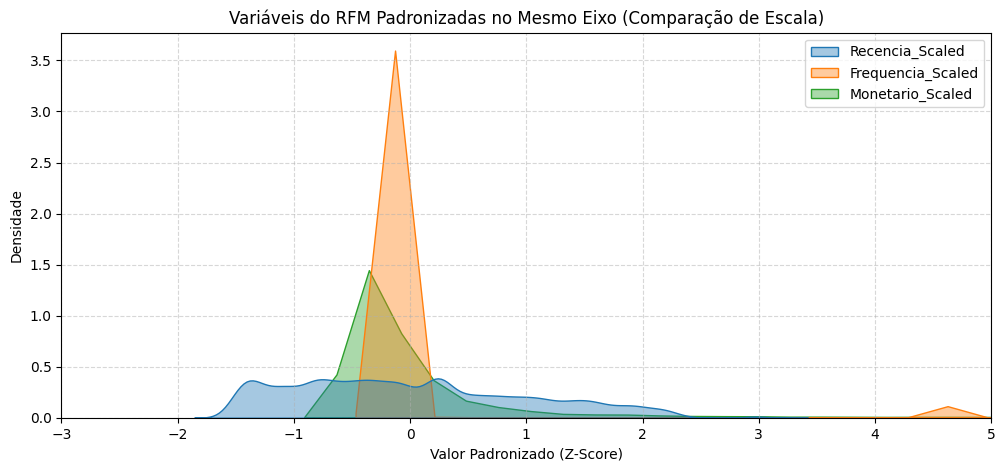

=== ESCALAS DOS EIXOS COMPARAÇÃO ===
Recência Original: Mín=1 | Máx=714
Recência Padronizada: Mín=-1.5528 | Máx=3.1198

Monetário Original: Mín=R$ 0.85 | Máx=R$ 13440.00
Monetário Padronizada: Mín=-0.6022 | Máx=54.1615


In [ ]:
# Plotando as três variáveis padronizadas juntas no mesmo gráfico.
# Todas compartilham a mesma escala (eixo X único).

plt.figure(figsize=(12, 5))
sns.kdeplot(data=df_rfm_scaled[['Recencia_Scaled', 'Frequencia_Scaled', 'Monetario_Scaled']], fill=True, common_norm=False, alpha=0.4)
plt.title('Variáveis do RFM Padronizadas no Mesmo Eixo (Comparação de Escala)')
plt.xlabel('Valor Padronizado (Z-Score)')
plt.ylabel('Densidade')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-3, 5) # Foco na maior concentração dos dados
plt.show()

# Print explicativo dos limites
print("=== ESCALAS DOS EIXOS COMPARAÇÃO ===")
print(f"Recência Original: Mín={rfm['Recencia'].min()} | Máx={rfm['Recencia'].max()}")
print(f"Recência Padronizada: Mín={df_rfm_scaled['Recencia_Scaled'].min():.4f} | Máx={df_rfm_scaled['Recencia_Scaled'].max():.4f}\n")

print(f"Monetário Original: Mín=R$ {rfm['Monetario'].min():.2f} | Máx=R$ {rfm['Monetario'].max():.2f}")
print(f"Monetário Padronizada: Mín={df_rfm_scaled['Monetario_Scaled'].min():.4f} | Máx={df_rfm_scaled['Monetario_Scaled'].max():.4f}")

##Agrupando Clientes

In [ ]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Consolidar métricas por cliente utilizando Recência (dias desde a última compra), Quantidade de Itens, Valor Total Pago e Avaliação Média
data_referencia = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

clientes_cluster = df.groupby('customer_unique_id').agg(
    Recencia=('order_purchase_timestamp', lambda x: (data_referencia - x.max()).days),
    Quantidade_Itens=('product_id', 'count'), # total de itens comprados
    Faturamento_Total=('price', 'sum'), # valor pago em produtos
    Avaliacao_Media=('review_score', 'mean') # nota média de avaliação
).reset_index()

# Avaliações não preenchidas recebem a média geral
clientes_cluster['Avaliacao_Media'] = clientes_cluster['Avaliacao_Media'].fillna(df['review_score'].mean())

# 2. Padronizar as variáveis para o K-means
colunas_modelo = ['Recencia', 'Quantidade_Itens', 'Faturamento_Total', 'Avaliacao_Media']
scaler = StandardScaler()
dados_normalizados = scaler.fit_transform(clientes_cluster[colunas_modelo])

# 3. Aplicar o algoritmo K-means com 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clientes_cluster['Cluster'] = kmeans.fit_predict(dados_normalizados)

# 4. Analisar a média de cada variável por cluster para entender o perfil de cada grupo
analise_clusters = clientes_cluster.groupby('Cluster').agg(
    Qtd_Clientes=('customer_unique_id', 'count'),
    Recencia_Media=('Recencia', 'mean'),
    Itens_Medios=('Quantidade_Itens', 'mean'),
    Faturamento_Medio=('Faturamento_Total', 'mean'),
    Avaliacao_Media=('Avaliacao_Media', 'mean')
).reset_index()

display(analise_clusters)

,Cluster,Qtd_Clientes,Recencia_Media,Itens_Medios,Faturamento_Medio,Avaliacao_Media
0,0,15856,230.142154,1.267028,133.612208,1.743094
1,1,42494,122.946039,1.134042,120.818577,4.700409
2,2,32232,393.239327,1.144670,122.837061,4.634560
3,3,2776,239.652378,3.799712,959.858725,3.943409


In [ ]:
# 5. Mapear os clusters para as categorias com base nas características médias observadas:
# - Alto faturamento e alta frequência = VIP
# - Baixa recência (compra recente) e boa avaliação -= Clientes Fiéis
# - Alta recência (muito tempo sem comprar) e baixa nota -= Inativos / Em Risco de Churn

# Criando uma lógica dinâmica baseada nos rankings para nomear os clusters
centroides = clientes_cluster.groupby('Cluster')[['Faturamento_Total', 'Recencia', 'Avaliacao_Media', 'Quantidade_Itens']].mean()

# Identificar os índices baseado nos comportamentos dos centroides
vip_cluster = centroides['Faturamento_Total'].idxmax()
inativo_cluster = centroides['Recencia'].idxmax()

# Restantes para Fiéis e Em Risco de Churn (avaliamos satisfação e tempo de compra recente)
restantes = [i for i in range(4) if i not in [vip_cluster, inativo_cluster]]
if centroides.loc[restantes[0], 'Avaliacao_Media'] < centroides.loc[restantes[1], 'Avaliacao_Media']:
    churn_cluster = restantes[0]
    fieis_cluster = restantes[1]
else:
    churn_cluster = restantes[1]
    fieis_cluster = restantes[0]

mapeamento_clusters = {
    vip_cluster: 'VIP (Alto Gasto e Volume)',
    fieis_cluster: 'Clientes Fiéis (Ativos e Satisfeitos)',
    churn_cluster: 'Em Risco de Churn (Baixa Satisfação)',
    inativo_cluster: 'Inativos (Muito tempo sem comprar)'
}

clientes_cluster['Perfil_Cliente'] = clientes_cluster['Cluster'].map(mapeamento_clusters)

# Exibir a nova distribuição dos perfis
resumo_perfis = clientes_cluster['Perfil_Cliente'].value_counts().reset_index()
resumo_perfis.columns = ['Perfil', 'Quantidade de Clientes']
resumo_perfis['% do Total'] = (resumo_perfis['Quantidade de Clientes'] / resumo_perfis['Quantidade de Clientes'].sum()) * 100
display(resumo_perfis)

,Perfil,Quantidade de Clientes,% do Total
0,Clientes Fiéis (Ativos e Satisfeitos),42494,45.517256
1,Inativos (Muito tempo sem comprar),32232,34.525161
2,Em Risco de Churn (Baixa Satisfação),15856,16.984083
3,VIP (Alto Gasto e Volume),2776,2.973500


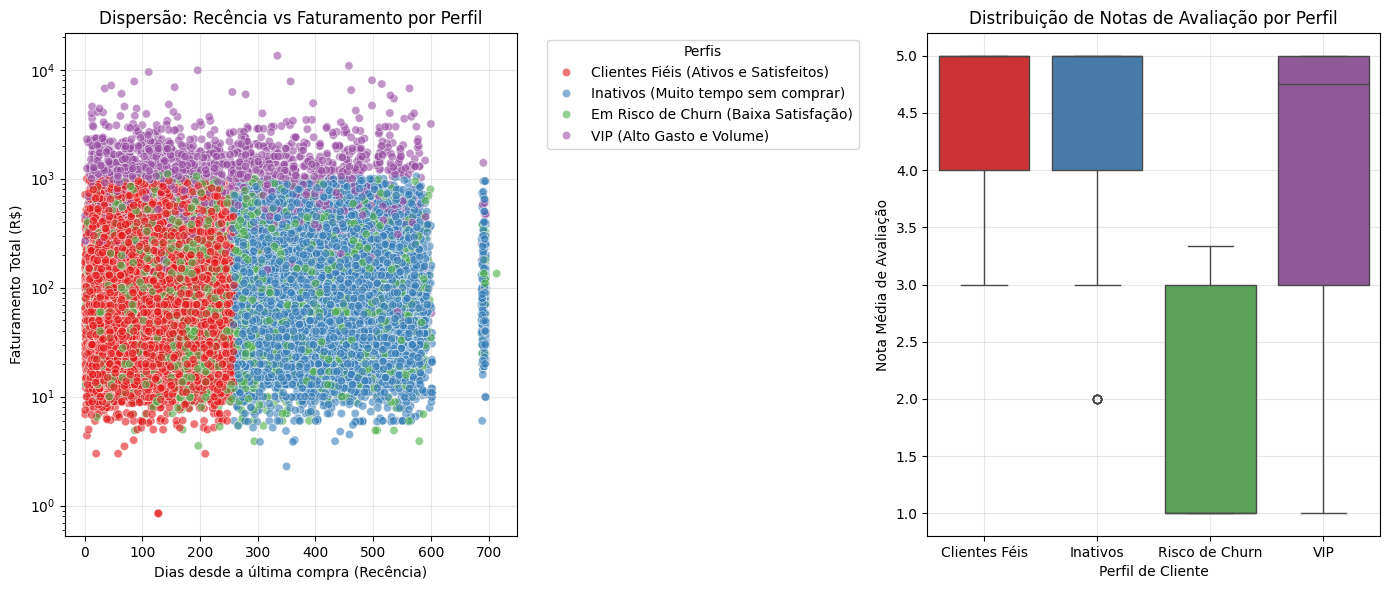

In [ ]:
# 6. Visualização Gráfica tridimensional simulada em 2D dos Perfis criados
plt.figure(figsize=(14, 6))

# Gráfico 1: Recência vs Faturamento por Perfil
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=clientes_cluster,
    x='Recencia',
    y='Faturamento_Total',
    hue='Perfil_Cliente',
    palette='Set1',
    alpha=0.6
)
plt.title('Dispersão: Recência vs Faturamento por Perfil')
plt.xlabel('Dias desde a última compra (Recência)')
plt.ylabel('Faturamento Total (R$)')
plt.yscale('log') # Escala logarítmica para melhor visualização dos outliers
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Perfis')

# Gráfico 2: Satisfação Média por Perfil com Rótulos Abreviados na Horizontal
plt.subplot(1, 2, 2)
ax2 = sns.boxplot(
    data=clientes_cluster,
    x='Perfil_Cliente',
    y='Avaliacao_Media',
    palette='Set1',
    hue='Perfil_Cliente',
    legend=False
)
plt.title('Distribuição de Notas de Avaliação por Perfil')
plt.xlabel('Perfil de Cliente')
plt.ylabel('Nota Média de Avaliação')

# Mapeamento de abreviações para o eixo X
rotulos_originais = [tick.get_text() for tick in ax2.get_xticklabels()]
mapa_abreviado = {
    'Clientes Fiéis (Ativos e Satisfeitos)': 'Clientes Féis',
    'Inativos (Muito tempo sem comprar)': 'Inativos',
    'Em Risco de Churn (Baixa Satisfação)': 'Risco de Churn',
    'VIP (Alto Gasto e Volume)': 'VIP'
}
rotulos_novos = [mapa_abreviado.get(label, label) for label in rotulos_originais]

# Definir as posições dos ticks para evitar avisos do Matplotlib antes de alterar os rótulos
ax2.set_xticks(range(len(rotulos_novos)))
ax2.set_xticklabels(rotulos_novos, rotation=0, ha='center')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()